# 05 — Modelos de Árvore: Árvore de Decisão, Random Forest e Gradient Boosting

Até aqui, usamos só a **regressão logística**, que chegou a uma **AUC de 0,906** no notebook 04. Mas ela é um modelo **linear**: cada coluna empurra a pontuação numa única direção. E vimos dois padrões que uma reta não consegue seguir:
- A **idade** tem uma relação em "U" invertido com a renda (notebook 01): sobe até os 45–55 anos e depois cai.
- O **ganho de capital** tem um "degrau" (notebook 03): 0% de renda alta entre 1 e 3 mil, ~98% acima de 7 mil.

No ML-01, os modelos de **árvore** resolveram problemas parecidos na regressão. Neste notebook vamos usá-los para **classificar**:
- A **árvore de decisão** e a **impureza de Gini**
- Por que a codificação **ordinal** volta a ser uma opção com árvores
- A **random forest**, e uma surpresa com as probabilidades dela
- O **gradient boosting** (`HistGradientBoostingClassifier`), que entende colunas categóricas e valores ausentes **sem pré-processamento**
- **Ajuste de hiperparâmetros** e a comparação final, sempre pela **AUC**

> ⏱️ **Este notebook demora cerca de 2 minutos para rodar**, porque treina centenas de árvores com validação cruzada. As células mais lentas estão indicadas.

## 1. Importando bibliotecas e preparando os dados

In [1]:
import time   # para medir quanto tempo cada modelo leva

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, validation_curve
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

# Ferramentas novas deste notebook (as árvores já são conhecidas do ML-01, agora na versão "Classifier"):
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.inspection import PartialDependenceDisplay
from scipy.stats import loguniform, randint   # distribuições para a busca aleatória (como no ML-01)

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100

df = fetch_openml("adult", version=2, as_frame=True).frame
X = df.drop(columns="class")
y = (df["class"] == ">50K").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

colunas_numericas = ["age", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
colunas_categoricas = ["workclass", "marital-status", "occupation", "relationship", "race", "sex", "native-country"]
colunas = colunas_numericas + colunas_categoricas

Para comparar os modelos, usamos a **AUC** como métrica principal, como decidimos no notebook 04: ela mede se o modelo **ordena** bem as pessoas, sem depender do limiar. Também guardamos a acurácia, a AUC no **treino** (para enxergar o overfitting) e o tempo.

In [2]:
resultados = {}            # resumo de cada modelo
auc_por_dobra = {}         # as 5 AUCs de cada modelo, para a comparação pareada no fim


def avaliar(nome, modelo):
    """Validação cruzada com AUC e acurácia; guarda e devolve o resumo."""
    inicio = time.time()
    cv_resultado = cross_validate(
        modelo, X_train[colunas], y_train, cv=cv,
        scoring=["roc_auc", "accuracy"],
        return_train_score=True,
    )
    auc_por_dobra[nome] = cv_resultado["test_roc_auc"]
    resultados[nome] = {
        "AUC validação": cv_resultado["test_roc_auc"].mean(),
        "± desvio": cv_resultado["test_roc_auc"].std(),
        "AUC treino": cv_resultado["train_roc_auc"].mean(),
        "acurácia": cv_resultado["test_accuracy"].mean(),
        "tempo (s)": time.time() - inicio,
    }
    return pd.DataFrame(resultados).T


# A referência: a logística do notebook 03.
logistica = Pipeline([
    ("preparar", ColumnTransformer([
        ("numericas", StandardScaler(), colunas_numericas),
        ("categoricas", Pipeline([
            ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
            ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
        ]), colunas_categoricas),
    ])),
    ("modelo", LogisticRegression(max_iter=1000)),
])
avaliar("Logística (nb 03)", logistica)

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Logística (nb 03),0.9064,0.0037,0.9077,0.8515,2.1235


## 🎓 Conceito: árvore de decisão para classificação

A árvore de decisão do ML-01 funciona do mesmo jeito aqui: ela faz uma sequência de **perguntas de sim ou não** sobre as colunas ("é casado?", "escolaridade ≤ 12?"), e cada caminho termina numa **folha**.

A diferença está no que a folha devolve:
- Na **regressão**, a folha devolve a **média** do alvo das casas que caíram nela.
- Na **classificação**, a folha devolve a **proporção de cada classe** entre as pessoas que caíram nela. Se 70 das 100 pessoas de uma folha ganham mais de 50 mil, a probabilidade prevista é **0,70**.

E como a árvore escolhe a melhor pergunta? Na regressão, ela buscava a divisão que mais reduzia o erro quadrático. Na classificação, ela busca a divisão que deixa os grupos mais **"puros"**, isto é, com uma classe predominando.

## 🎓 Conceito: impureza de Gini

A **impureza de Gini** mede o quanto um grupo está **misturado**:

$$\text{Gini} = 1 - p_0^2 - p_1^2$$

onde $p_0$ e $p_1$ são as proporções das duas classes no grupo.
- Grupo **puro** (todo mundo da mesma classe): Gini = 1 − 1² − 0² = **0**.
- Grupo **meio a meio**: Gini = 1 − 0,5² − 0,5² = **0,5**, o máximo para duas classes.
- Nosso treino inteiro (24% × 76%): Gini = 1 − 0,24² − 0,76² ≈ **0,36**.

Em cada nó, a árvore testa todas as perguntas possíveis e escolhe a que mais **reduz** a impureza média dos dois grupos resultantes.

Analogia: separar uma pilha de roupas misturadas, brancas e coloridas. A melhor primeira pergunta é a que deixa cada pilha resultante com a cor mais uniforme possível.

## 2. Uma árvore pequena, para enxergar as perguntas

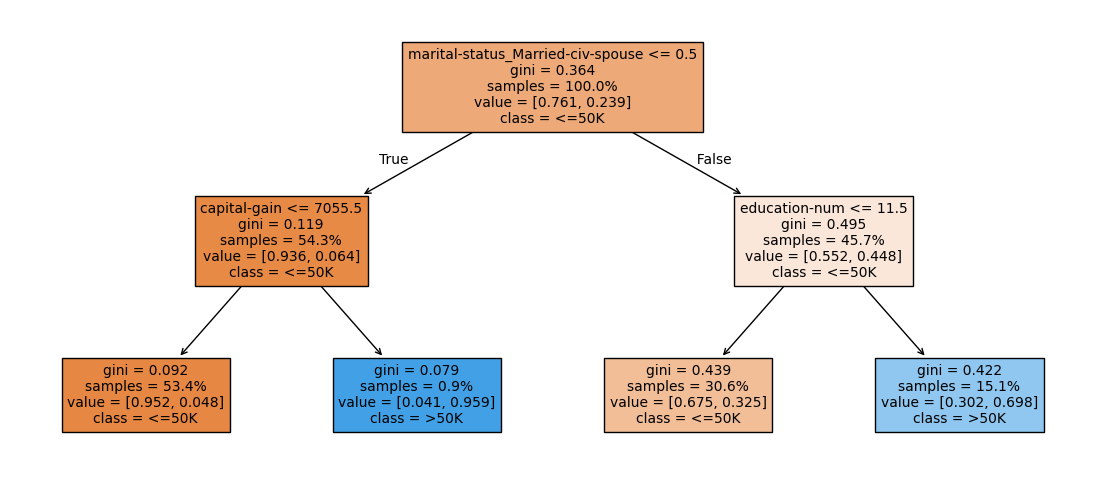

In [3]:
# Para a árvore pequena usamos o one-hot do notebook 03, porque as perguntas ficam fáceis de ler
# (ex.: "marital-status_Married-civ-spouse <= 0.5" significa "NÃO é casado").
preparar_one_hot = ColumnTransformer([
    ("numericas", "passthrough", colunas_numericas),   # "passthrough": deixa as colunas como estão
    ("categoricas", Pipeline([
        ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("one_hot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50)),
    ]), colunas_categoricas),
], verbose_feature_names_out=False)   # nomes de coluna sem o prefixo "numericas__"/"categoricas__"

arvore_pequena = Pipeline([
    ("preparar", preparar_one_hot),
    ("modelo", DecisionTreeClassifier(max_depth=2, random_state=42)),
])
arvore_pequena.fit(X_train[colunas], y_train)

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(
    arvore_pequena.named_steps["modelo"],
    feature_names=arvore_pequena.named_steps["preparar"].get_feature_names_out(),
    class_names=["<=50K", ">50K"],
    filled=True,        # pinta cada caixa com a cor da classe predominante
    impurity=True,      # mostra o Gini de cada nó
    proportion=True,    # mostra proporções em vez de contagens
    fontsize=10,
    ax=ax,
)
plt.show()

**Conclusão:** a árvore pequena descobriu sozinha os padrões mais fortes da análise exploratória:
- **A primeira pergunta é "é casado?"** (`Married-civ-spouse`). Ela divide o treino (Gini 0,364, perto dos 0,36 calculados acima) em dois grupos bem diferentes: entre os **não casados** (54,3% das pessoas), só 6,4% têm renda alta; entre os **casados** (45,7%), são 44,8%.
- **Entre os não casados, a pergunta seguinte é o ganho de capital acima de ~7 mil.** É o "degrau" do notebook 03! Os poucos com ganho alto (0,9% das pessoas) têm **95,9%** de renda alta, e o resto, só 4,8%.
- **Entre os casados, a pergunta é a escolaridade** (`education-num` > 11,5, ou seja, a partir de `Assoc-acdm`). Com mais estudo, a taxa sobe de 32,5% para **69,8%**.

Repare que a árvore usa **perguntas diferentes em cada ramo**: o ganho de capital importa mais para os não casados, e a escolaridade, para os casados. Essas **interações** são algo que a regressão logística, que soma os efeitos de cada coluna, não consegue representar diretamente.

## 3. A árvore sem limite: overfitting extremo (de novo)

In [4]:
arvore_sem_limite = Pipeline([
    ("preparar", preparar_one_hot),
    ("modelo", DecisionTreeClassifier(random_state=42)),   # sem max_depth: cresce até as folhas ficarem puras
])
avaliar("Árvore sem limite", arvore_sem_limite)

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Logística (nb 03),0.9064,0.0037,0.9077,0.8515,2.1235
Árvore sem limite,0.7660,0.0057,0.9983,0.8183,4.9122


In [5]:
# Por que a AUC é tão baixa? Vejamos as probabilidades que essa árvore produz.
arvore_sem_limite.fit(X_train[colunas], y_train)
prob_arvore = arvore_sem_limite.predict_proba(X_train[colunas])[:, 1]
print(f"Profundidade da árvore: {arvore_sem_limite.named_steps['modelo'].get_depth()}")
print(f"Folhas: {arvore_sem_limite.named_steps['modelo'].get_n_leaves():,}")
# np.isin verifica, para cada valor, se ele está na lista dada.
print(f"Probabilidades no treino que são exatamente 0 ou 1: {np.isin(prob_arvore, [0, 1]).mean():.1%}")

Profundidade da árvore: 49
Folhas: 6,853
Probabilidades no treino que são exatamente 0 ou 1: 92.9%


**Conclusão:** como no ML-01, a árvore sem limite **decora** o treino: AUC de **0,998** no treino contra só **0,766** na validação, a pior AUC de todos os modelos até aqui, bem abaixo da logística (0,906). Ela cresceu até **49 níveis** de profundidade, com **6.853 folhas**.

E há um problema específico da classificação: como as folhas ficaram puras, **92,9%** das probabilidades no treino são **exatamente 0 ou 1**. O modelo não diz "70% de chance", só "certeza absoluta" de um lado ou do outro. Com tantos empates, ele não consegue **ordenar** as pessoas, e é por isso que a AUC despenca.

## 4. Curva de complexidade: qual a melhor profundidade?

Como no ML-01, usamos o `validation_curve` para testar várias profundidades com validação cruzada, agora com a AUC. Aqui usamos a codificação **ordinal**, e a próxima seção explica por quê.

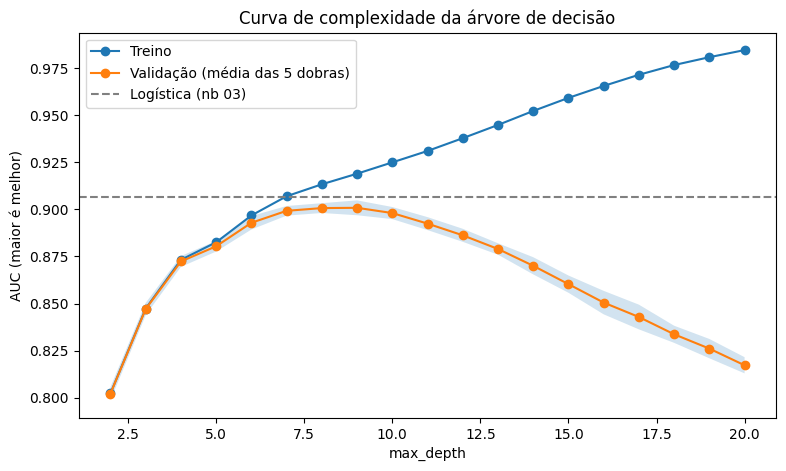

,AUC treino,AUC validação,± desvio
6,0.8967,0.8929,0.0036
7,0.9069,0.8992,0.0026
8,0.9133,0.9007,0.0026
9,0.9189,0.9008,0.0039
10,0.9249,0.8980,0.0032
11,0.9310,0.8924,0.0034


In [6]:
# Para as árvores, numerar as categorias funciona bem (seção 5).
preparar_ordinal = ColumnTransformer([
    ("numericas", "passthrough", colunas_numericas),
    ("categoricas", Pipeline([
        ("preencher", SimpleImputer(strategy="constant", fill_value="Desconhecido")),
        ("numerar", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)),
    ]), colunas_categoricas),
])

profundidades = np.arange(2, 21)
scores_treino, scores_val = validation_curve(
    Pipeline([("preparar", preparar_ordinal), ("modelo", DecisionTreeClassifier(random_state=42))]),
    X_train[colunas], y_train,
    param_name="modelo__max_depth",   # o hiperparâmetro "max_depth" da etapa "modelo" do pipeline
    param_range=profundidades,
    cv=cv, scoring="roc_auc",
    n_jobs=-1,   # usa todos os núcleos do processador, treinando várias árvores ao mesmo tempo
)
auc_treino, auc_val, desvio_val = scores_treino.mean(axis=1), scores_val.mean(axis=1), scores_val.std(axis=1)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(profundidades, auc_treino, marker="o", label="Treino")
ax.plot(profundidades, auc_val, marker="o", label="Validação (média das 5 dobras)")
ax.fill_between(profundidades, auc_val - desvio_val, auc_val + desvio_val, alpha=0.2)
ax.axhline(resultados["Logística (nb 03)"]["AUC validação"], color="gray", linestyle="--", label="Logística (nb 03)")
ax.set_xlabel("max_depth")
ax.set_ylabel("AUC (maior é melhor)")
ax.set_title("Curva de complexidade da árvore de decisão")
ax.legend()
plt.show()

pd.DataFrame({"AUC treino": auc_treino, "AUC validação": auc_val, "± desvio": desvio_val},
             index=profundidades).loc[6:11]

**Conclusão:** a curva tem o mesmo formato do ML-01: a AUC no treino sobe sem parar, e a validação sobe até **`max_depth` 8–9** e depois cai (overfitting). As profundidades 8 e 9 estão **empatadas** (0,9007 e 0,9008, com desvios de ~0,003), então escolhemos a **mais simples**, `max_depth=8`.

Uma surpresa: **mesmo a melhor árvore (0,901) não chega à logística (0,906)**, a linha tracejada. Uma árvore sozinha, com só 8 perguntas em sequência, é um modelo "grosseiro": ela divide as pessoas em no máximo 256 grupos e dá a mesma probabilidade para todo mundo dentro de cada grupo. Para vencer a logística, vamos precisar de **muitas** árvores.

## 🎓 Conceito: árvores não se importam com a ordem inventada

No notebook 03, a codificação **ordinal** atrapalhou a regressão logística porque inventava uma ordem: o modelo só conseguia dizer "quanto maior o número da profissão, mais renda".

Com árvores, a história é outra. Uma árvore não multiplica a coluna por um coeficiente: ela faz **cortes** ("profissão ≤ 3,5?"). Com dois ou três cortes seguidos, ela consegue **isolar** qualquer categoria, como "profissão entre 2,5 e 3,5", ou seja, exatamente `Exec-managerial`. A ordem inventada atrapalha um pouco (pode precisar de mais cortes), mas não impede a árvore de aprender.

E há uma vantagem prática: com o one-hot, cada coluna categórica vira dezenas de colunas, e a árvore precisa testar cortes em **todas**. Com o ordinal, são só 12 colunas. Isso deixa o treino **bem mais rápido**, principalmente com centenas de árvores, como na random forest.

## 5. One-hot × ordinal nas árvores

In [7]:
for nome_codificacao, preparar in [("one-hot", preparar_one_hot), ("ordinal", preparar_ordinal)]:
    avaliar(f"Árvore max_depth=8 ({nome_codificacao})", Pipeline([
        ("preparar", preparar),
        ("modelo", DecisionTreeClassifier(max_depth=8, random_state=42)),
    ]))
# ⏱️ A random forest com one-hot é a célula mais lenta até aqui (~30 segundos).
for nome_codificacao, preparar in [("one-hot", preparar_one_hot), ("ordinal", preparar_ordinal)]:
    avaliar(f"Random forest ({nome_codificacao})", Pipeline([
        ("preparar", preparar),
        ("modelo", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)),
    ]))

# .str.contains mantém só as linhas cujo nome contém o texto; dentro do texto, o "|" significa "ou".
tabela = pd.DataFrame(resultados).T
tabela[tabela.index.str.contains("max_depth=8|Random forest")]

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Árvore max_depth=8 (one-hot),0.9024,0.0019,0.9143,0.8566,1.6825
Árvore max_depth=8 (ordinal),0.9007,0.0026,0.9133,0.8532,0.7567
Random forest (one-hot),0.8938,0.0054,0.9973,0.8472,28.1859
Random forest (ordinal),0.8969,0.0051,0.9974,0.8496,6.0103


**Conclusão:** - **Na árvore única**, o one-hot ficou um pouco à frente (AUC 0,9024 contra 0,9007), mas a diferença é do tamanho do desvio padrão (~0,002–0,003). Na prática, empate, e o ordinal foi **2 vezes mais rápido**.
- **Na random forest**, o ordinal foi um pouco **melhor** (0,8969 contra 0,8938) e quase **5 vezes mais rápido** (~6 s contra ~30 s, somando as 5 dobras).

Para árvores, então, a codificação **ordinal** é a escolha prática. A lição do notebook 03 (one-hot para colunas nominais) vale para **modelos lineares**.

⚠️ Mas repare no resultado da random forest: AUC de **0,897**, **abaixo** da árvore única de profundidade 8 e da logística! E a AUC no treino é 0,997, um sinal claro de overfitting. Algo está errado, e a próxima seção explica o quê.

## 6. A random forest e as suas probabilidades

Por que a random forest, que no ML-01 venceu com folga a árvore única, aqui ficou **abaixo** dela e até da logística?

Por padrão, cada árvore da floresta cresce **sem limite**, até as folhas ficarem puras (seção 3). Então **cada árvore** vota só 0 ou 1, e a probabilidade da floresta é a **fração de árvores** que votaram em renda alta. No treino, as árvores decoraram cada pessoa, e por isso elas concordam demais entre si sobre pessoas parecidas com as do treino, gerando probabilidades **exageradamente confiantes**. Isso prejudica justamente a **ordenação** que a AUC mede.

O hiperparâmetro **`min_samples_leaf`** resolve isso: ele exige que cada folha tenha **pelo menos** um número mínimo de pessoas. Assim, as folhas guardam **proporções** de verdade (ex.: 7 de 10 com renda alta = 0,7), e não só 0 ou 1.

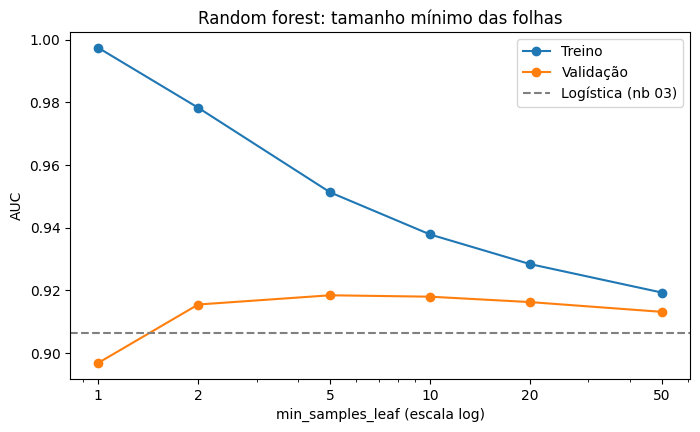

,AUC treino,AUC validação,± desvio
1,0.9974,0.8969,0.0051
2,0.9783,0.9155,0.0039
5,0.9513,0.9185,0.0031
10,0.9379,0.9180,0.0029
20,0.9284,0.9163,0.0030
50,0.9193,0.9132,0.0027


In [8]:
# ⏱️ Célula lenta (~30 segundos): 6 valores × 5 dobras × 200 árvores.
folhas_minimas = [1, 2, 5, 10, 20, 50]
scores_treino, scores_val = validation_curve(
    Pipeline([("preparar", preparar_ordinal),
              ("modelo", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42))]),
    X_train[colunas], y_train,
    param_name="modelo__min_samples_leaf", param_range=folhas_minimas,
    cv=cv, scoring="roc_auc",
)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(folhas_minimas, scores_treino.mean(axis=1), marker="o", label="Treino")
ax.plot(folhas_minimas, scores_val.mean(axis=1), marker="o", label="Validação")
ax.axhline(resultados["Logística (nb 03)"]["AUC validação"], color="gray", linestyle="--", label="Logística (nb 03)")
ax.set_xscale("log")    # escala logarítmica no eixo x: 1, 10 e 100 ficam igualmente espaçados
ax.set_xticks(folhas_minimas, folhas_minimas)
ax.set_xlabel("min_samples_leaf (escala log)")
ax.set_ylabel("AUC")
ax.set_title("Random forest: tamanho mínimo das folhas")
ax.legend()
plt.show()

pd.DataFrame({"AUC treino": scores_treino.mean(axis=1), "AUC validação": scores_val.mean(axis=1),
              "± desvio": scores_val.std(axis=1)}, index=folhas_minimas)

**Conclusão:** `min_samples_leaf` faz uma diferença enorme:
- Com o padrão (**1**), a AUC de validação é **0,8969**, e no treino é 0,997.
- Com **5** ou **10**, a validação sobe para **0,9185** e **0,9180**, agora bem **acima** da logística. A AUC no treino cai para 0,95 e 0,94: as árvores decoram muito menos.
- Com folhas grandes demais (**50**), a validação volta a cair (0,9132): as árvores ficam simples demais (underfitting).

Os valores 5 e 10 estão **empatados** (diferença de 0,0005, contra desvios de ~0,003). Escolhemos **10**, que gera árvores menores, ou seja, o modelo mais simples.

**Lição:** no ML-01, a random forest padrão funcionou bem porque, na regressão, a média de muitas árvores profundas já é um bom número. Na classificação, quando o que importa são as **probabilidades** (e a ordenação que a AUC mede), folhas puras atrapalham. Os padrões de um algoritmo **nem sempre servem** para todo problema.

In [9]:
floresta = Pipeline([
    ("preparar", preparar_ordinal),
    ("modelo", RandomForestClassifier(n_estimators=200, min_samples_leaf=10, n_jobs=-1, random_state=42)),
])
# Mostramos só as florestas: .tail(3) pega as 3 últimas linhas da tabela.
avaliar("Random forest (min_samples_leaf=10)", floresta).tail(3)

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Random forest (one-hot),0.8938,0.0054,0.9973,0.8472,28.1859
Random forest (ordinal),0.8969,0.0051,0.9974,0.8496,6.0103
Random forest (min_samples_leaf=10),0.9180,0.0029,0.9379,0.8640,4.9540


## 🎓 Conceito: gradient boosting para classificação

No ML-01 (notebook 08), vimos o **boosting**: em vez de árvores independentes que votam (a floresta), ele treina árvores **em sequência**, cada uma corrigindo os erros das anteriores. Na classificação, a ideia é a mesma, só que as árvores corrigem a **pontuação** (o $z$ da regressão logística), que depois passa pela sigmoide para virar probabilidade.

O `HistGradientBoostingClassifier` tem duas vantagens enormes para o Adult:
- **Entende colunas categóricas sozinho:** com `categorical_features="from_dtype"`, ele reconhece as colunas do tipo `category` do pandas e faz cortes do tipo "profissão está no grupo {A, C, F}?", sem ordem inventada e sem one-hot.
- **Aceita valores ausentes:** em cada corte, ele aprende para qual lado mandar os `NaN`.

Ou seja: para ele, **não precisamos de nenhum pré-processamento**. Passamos a tabela original e pronto.

## 7. Gradient boosting com as configurações padrão

In [10]:
# Sem Pipeline, sem ColumnTransformer: as colunas category do pandas vão direto para o modelo.
boosting = HistGradientBoostingClassifier(categorical_features="from_dtype", random_state=42)
avaliar("Gradient boosting (padrão)", boosting).loc[
    ["Logística (nb 03)", "Random forest (min_samples_leaf=10)", "Gradient boosting (padrão)"]
]

,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Logística (nb 03),0.9064,0.0037,0.9077,0.8515,2.1235
Random forest (min_samples_leaf=10),0.9180,0.0029,0.9379,0.8640,4.9540
Gradient boosting (padrão),0.9285,0.0029,0.9454,0.8718,3.2166


**Conclusão:** com as configurações padrão, sem nenhum pré-processamento, o gradient boosting chega a **AUC 0,9285 ± 0,0029**, o melhor resultado até agora: acima da floresta ajustada (0,9180) e da logística (0,9064). A acurácia também é a maior: **87,18%**.

E ele foi **rápido**: 3 segundos nas 5 dobras, contra 5 segundos da floresta. Tudo isso entregando a tabela original, com texto e valores ausentes, direto para o modelo.

## 8. Ajuste de hiperparâmetros: vale a pena?

No ML-01 (notebook 08), ajustar os hiperparâmetros do boosting trouxe um ganho real. Vamos tentar aqui com uma **busca aleatória** (`RandomizedSearchCV`), testando 20 combinações com validação cruzada.

In [11]:
# ⏱️ Célula lenta (~30 segundos): 20 combinações × 5 dobras = 100 modelos.
espaco_busca = {
    "learning_rate": loguniform(0.02, 0.3),       # taxa de aprendizado, sorteada em escala log
    "max_iter": randint(100, 600),                # número de árvores
    "max_leaf_nodes": randint(8, 64),             # tamanho de cada árvore
    "min_samples_leaf": randint(10, 200),         # tamanho mínimo das folhas
    "l2_regularization": loguniform(1e-3, 10),    # regularização (como o Ridge do ML-01, notebook 09)
}
busca = RandomizedSearchCV(
    # early_stopping=False: usa exatamente o max_iter sorteado, sem parar antes.
    HistGradientBoostingClassifier(categorical_features="from_dtype", early_stopping=False, random_state=42),
    espaco_busca,
    n_iter=20, cv=cv, scoring="roc_auc", n_jobs=-1, random_state=42,
)
busca.fit(X_train[colunas], y_train)

print(f"Melhor AUC da busca: {busca.best_score_:.4f}")
print(f"AUC com o padrão:    {resultados['Gradient boosting (padrão)']['AUC validação']:.4f}")
print("Melhores hiperparâmetros:")
for nome, valor in busca.best_params_.items():
    print(f"   {nome}: {valor:.4g}")   # :.4g mostra até 4 algarismos significativos

Melhor AUC da busca: 0.9288
AUC com o padrão:    0.9285
Melhores hiperparâmetros:
   l2_regularization: 0.1866
   learning_rate: 0.02177
   max_iter: 501
   max_leaf_nodes: 33
   min_samples_leaf: 53


In [12]:
# cv_results_ guarda o resultado de todas as combinações testadas.
todas = pd.DataFrame(busca.cv_results_).sort_values("rank_test_score")
print(f"As 20 combinações tiveram AUC entre {todas['mean_test_score'].min():.4f} e {todas['mean_test_score'].max():.4f}")
todas[["param_learning_rate", "param_max_iter", "param_max_leaf_nodes", "mean_test_score", "std_test_score"]].head(5)

As 20 combinações tiveram AUC entre 0.9163 e 0.9288


,param_learning_rate,param_max_iter,param_max_leaf_nodes,mean_test_score,std_test_score
13,0.0218,501,33,0.9288,0.0028
18,0.0343,571,18,0.9288,0.0028
1,0.0669,314,18,0.9287,0.0026
17,0.0313,444,14,0.9285,0.0030
8,0.0677,373,11,0.9284,0.0028


**Conclusão:** **o ajuste quase não mudou nada.** A melhor combinação chegou a AUC **0,9288**, contra **0,9285** do padrão: uma diferença de 0,0003, **dez vezes menor** que o desvio padrão entre as dobras (~0,003). As 5 melhores combinações ficaram todas entre 0,9284 e 0,9288, ou seja, há muitas configurações igualmente boas, e o padrão já é uma delas.

Lembre também da "maldição do vencedor" do ML-01 (notebook 06): a melhor de 20 tentativas é, em parte, a mais **sortuda**. Com uma vantagem tão pequena, o resultado dela num conjunto novo provavelmente seria igual ao do padrão.

**Decisão:** ficamos com o boosting **padrão**, que é mais simples e igualmente bom. É a mesma lição do ML-01: ajustar hiperparâmetros só vale a pena quando a diferença é maior que o ruído.

## 9. Comparando todos os modelos

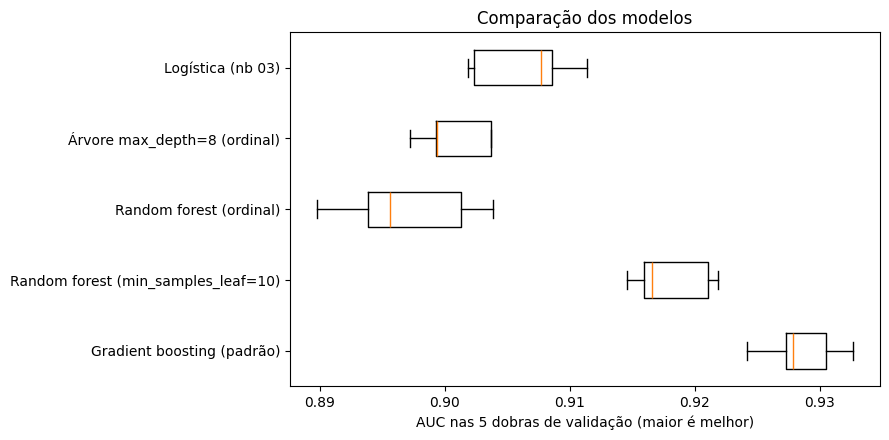

Boosting − logística, dobra a dobra: [0.0219 0.0213 0.0202 0.0254 0.0219]
O boosting venceu em 5 de 5 dobras


,AUC validação,± desvio,AUC treino,acurácia,tempo (s)
Logística (nb 03),0.9064,0.0037,0.9077,0.8515,2.1235
Árvore max_depth=8 (ordinal),0.9007,0.0026,0.9133,0.8532,0.7567
Random forest (ordinal),0.8969,0.0051,0.9974,0.8496,6.0103
Random forest (min_samples_leaf=10),0.9180,0.0029,0.9379,0.8640,4.9540
Gradient boosting (padrão),0.9285,0.0029,0.9454,0.8718,3.2166


In [13]:
nomes_finais = ["Logística (nb 03)", "Árvore max_depth=8 (ordinal)", "Random forest (ordinal)",
                "Random forest (min_samples_leaf=10)", "Gradient boosting (padrão)"]

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot([auc_por_dobra[n] for n in nomes_finais], vert=False)
ax.set_yticks(range(1, len(nomes_finais) + 1), nomes_finais)
ax.set_xlabel("AUC nas 5 dobras de validação (maior é melhor)")
ax.set_title("Comparação dos modelos")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

# Comparação pareada (ML-01, notebook 05): o boosting vence a logística em quantas dobras?
diferencas = auc_por_dobra["Gradient boosting (padrão)"] - auc_por_dobra["Logística (nb 03)"]
print("Boosting − logística, dobra a dobra:", diferencas.round(4))
print(f"O boosting venceu em {(diferencas > 0).sum()} de 5 dobras")

pd.DataFrame(resultados).T.loc[nomes_finais]

**Conclusão:** - **O gradient boosting vence todos.** Mesmo a pior dobra dele (~0,924) é melhor que a melhor dobra da logística (~0,911).
- **A comparação pareada confirma:** o boosting venceu a logística nas **5 dobras**, sempre por **0,020 a 0,025** de AUC. Não é sorte da divisão.
- A **ordem final** é: árvore única (0,901) e floresta padrão (0,897) < logística (0,906) < floresta ajustada (0,918) < **boosting (0,929)**.
- O boosting também tem a maior **acurácia** (87,18%, contra 85,15% da logística).

## 10. Por que o boosting vence? Olhando as curvas aprendidas

No ML-01 (notebook 07), conhecemos a **dependência parcial**: o gráfico que mostra como a previsão média muda quando variamos **uma** coluna, mantendo as outras como estão. Vamos usá-la para comparar o que a logística e o boosting aprenderam sobre a **idade** e o **ganho de capital**, os dois padrões "não lineares" do começo do notebook.

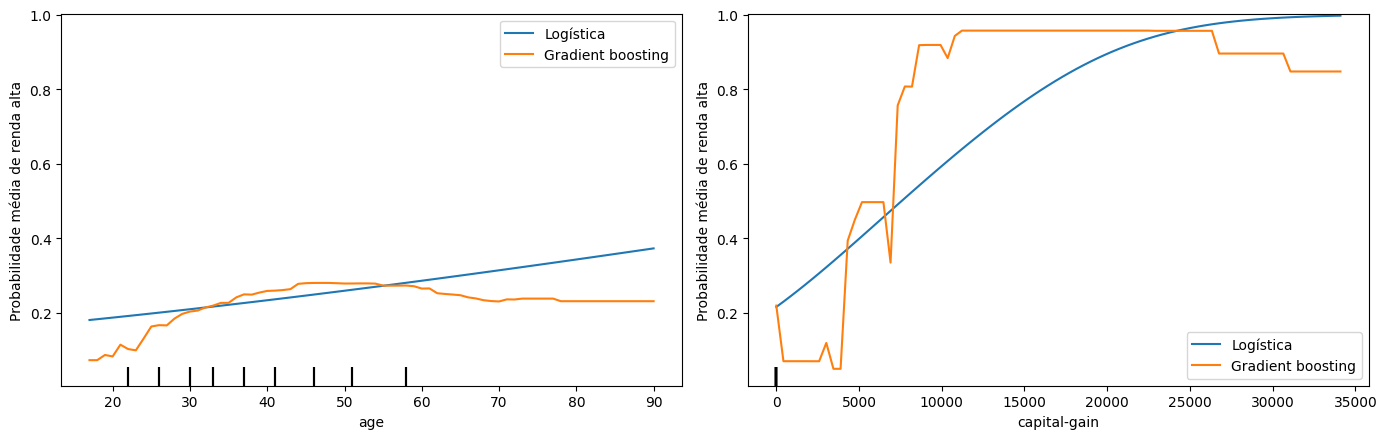

In [14]:
logistica.fit(X_train[colunas], y_train)
boosting.fit(X_train[colunas], y_train)

# O PartialDependenceDisplay pede que as colunas analisadas sejam decimais (float), e não inteiras.
# .astype({coluna: tipo}) converte só as colunas indicadas.
X_curvas = X_train[colunas].astype({"age": float, "capital-gain": float})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for modelo, nome, cor in [(logistica, "Logística", "tab:blue"), (boosting, "Gradient boosting", "tab:orange")]:
    PartialDependenceDisplay.from_estimator(
        modelo, X_curvas, ["age", "capital-gain"],
        response_method="predict_proba",          # a curva mostra a probabilidade de renda alta
        method="brute",                            # calcula "na força bruta": necessário para usar predict_proba
        grid_resolution=80,                        # quantos valores testar em cada coluna
        percentiles=(0, 0.995),                    # ignora os 0,5% de valores mais extremos
        ax=axes, line_kw={"label": nome, "color": cor},
    )
for ax in axes:
    ax.set_ylabel("Probabilidade média de renda alta")
    ax.legend()
plt.tight_layout()
plt.show()

**Conclusão:** a dependência parcial mostra exatamente as limitações que motivaram este notebook:
- **Idade (esquerda):** a logística só sabe desenhar uma curva que sobe sempre, de 0,18 aos 17 anos até 0,37 aos 90. O boosting aprendeu o **"U" invertido**: a probabilidade sobe até ~0,28 por volta dos 45–55 anos e **cai** depois dos 60, para ~0,23.
- **Ganho de capital (direita):** a logística desenha uma curva em "S" suave. O boosting aprendeu o **degrau**: com ganho entre ~1 e 4 mil, a probabilidade **cai** para ~0,07 (abaixo de quem tem ganho zero, ~0,22), e acima de ~7 mil ela **salta** para ~0,9.

O boosting não "sabe" nada sobre idade ou investimentos: ele simplesmente tem liberdade para desenhar curvas de **qualquer formato**, e os dados mostraram qual formato é o certo. É por isso que ele vence a logística.

⚠️ O outro lado dessa liberdade aparece na curva do ganho de capital: alguns "dentes" (como a queda perto de 7 mil e acima de 26 mil) provavelmente são **ruído** de regiões com poucas pessoas. Com mais liberdade, vem mais risco de aprender detalhes que não se repetem.

## 11. Resumo e próximos passos

**Resultados (validação cruzada no treino)**

| Modelo | AUC | Acurácia |
|---|---|---|
| Árvore sem limite | 0,766 | 81,83% |
| Random forest (padrão) | 0,897 | 84,96% |
| Árvore `max_depth=8` | 0,901 | 85,32% |
| Logística (nb 03) | 0,906 | 85,15% |
| Random forest (`min_samples_leaf=10`) | 0,918 | 86,40% |
| **Gradient boosting (padrão)** | **0,929 ± 0,003** | **87,18%** |
| Gradient boosting (ajustado) | 0,929 | — |

**Conceitos que você aprendeu**
- **Árvore de decisão para classificação:** as folhas devolvem a **proporção** de cada classe.
- **Impureza de Gini:** como a árvore mede a "mistura" de um grupo.
- Folhas puras geram probabilidades **0 ou 1**, que destroem a ordenação e a AUC.
- Para árvores, a **codificação ordinal** funciona bem e é bem mais rápida que o one-hot.
- **`min_samples_leaf`** na random forest: essencial quando o que importa são as probabilidades.
- **`HistGradientBoostingClassifier`** com colunas categóricas e valores ausentes **nativos**.
- Ajustar hiperparâmetros **não** ajudou aqui: a diferença ficou muito abaixo do ruído.
- A **dependência parcial** mostra **por que** um modelo vence o outro.

**Python novo:** `import time` e `time.time()`, `plot_tree`, `"passthrough"`, `verbose_feature_names_out`, `get_depth`/`get_n_leaves`, `np.isin`, `n_jobs=-1`, `set_xscale("log")`, `.str.contains` com `|`, `.tail()`, o formato `:.4g`, `cv_results_` e `.astype({coluna: tipo})`.

**O que ainda falta investigar**
- ⚠️ Os modelos devolvem **probabilidades**, e usamos essas probabilidades para escolher limiares (notebook 04). Mas uma probabilidade de 70% significa mesmo que 70% dessas pessoas têm renda alta? Já vimos que a árvore sem limite exagerava.
- ⚠️ As classes são **desbalanceadas** (24% × 76%). Uma recomendação comum é "equilibrar as classes" com **pesos**. Será que isso ajuda?

**Próximo notebook (06):** probabilidades e classes desbalanceadas. Vamos conhecer a **calibração** (as probabilidades do modelo merecem confiança?), a **perda logarítmica** e testar, com honestidade, o **`class_weight="balanced"`** e outras ideias para lidar com o desbalanceamento.